# ☕ Classificação de torra de café com visão computacional — Semana 1

**Objetivo:** treinar um classificador de nível de torra (verde, clara, média, escura) e comparar três abordagens:

1. **Teachable Machine** — sem código (referência)
2. **Modelo treinado** — rede pré-treinada ajustada com fast.ai
3. **Modelo multimodal genérico** — Claude, só com instrução em texto, sem treino

**Base:** *Coffee Bean Dataset Resized (224×224)*, Kaggle — 1.600 imagens, 400 por classe (300 treino + 100 teste), arábica do Laos. Licença CC BY-SA 4.0.

**Antes de começar (VS Code):** clique em *Select Kernel* (canto superior direito) → *Colab* → escolha um ambiente com **GPU T4** → entre com sua conta Google.

O código roda no servidor do Colab, não no seu computador: o que for salvo em `/content` some quando a sessão termina.

## 1. Preparação

In [1]:
# Confere se a GPU está ativa (deve aparecer "Tesla T4" ou similar)
!nvidia-smi --query-gpu=name --format=csv,noheader
!pip install -q kagglehub anthropic

NVIDIA GeForce GTX 1650



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import random, shutil
import kagglehub

# Baixa a base do Kaggle. Se pedir login, rode antes: kagglehub.login()
caminho = kagglehub.dataset_download("gpiosenka/coffee-bean-dataset-resized-224-x-224")
base = Path(caminho)

# Localiza as pastas de treino e de teste, onde quer que estejam
train_dir = next(p for p in base.rglob("train") if p.is_dir())
test_dir  = next(p for p in base.rglob("test") if p.is_dir())
print("Treino:", train_dir)
print("Teste: ", test_dir)

Using Colab cache for faster access to the 'coffee-bean-dataset-resized-224-x-224' dataset.
Treino: /kaggle/input/coffee-bean-dataset-resized-224-x-224/train
Teste:  /kaggle/input/coffee-bean-dataset-resized-224-x-224/test


## 2. Conhecendo os dados

Antes de treinar qualquer coisa: quantas imagens há por classe, e como elas são? Esse passo é onde se descobre a maioria dos problemas.

In [3]:
from collections import Counter
EXT = {".jpg", ".jpeg", ".png"}
def imagens(pasta):
    return [f for f in Path(pasta).rglob("*") if f.suffix.lower() in EXT]

for nome, pasta in [("Treino", train_dir), ("Teste", test_dir)]:
    contagem = Counter(f.parent.name for f in imagens(pasta))
    print(nome, dict(sorted(contagem.items())))

Treino {'Dark': 300, 'Green': 300, 'Light': 300, 'Medium': 300}
Teste {'Dark': 100, 'Green': 100, 'Light': 100, 'Medium': 100}


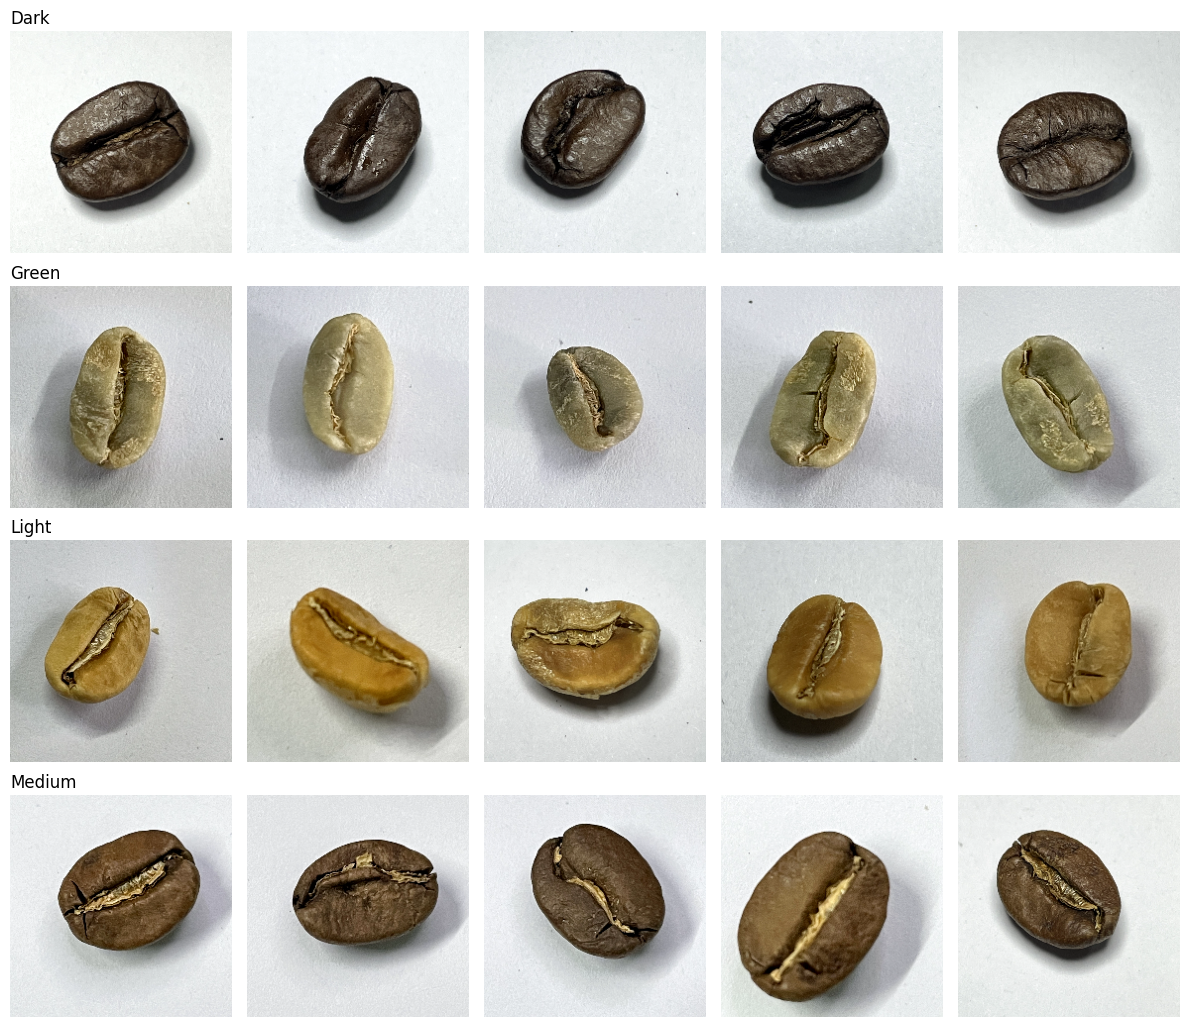

In [4]:
import matplotlib.pyplot as plt
from PIL import Image

classes = sorted(p.name for p in train_dir.iterdir() if p.is_dir())
random.seed(0)
fig, axes = plt.subplots(len(classes), 5, figsize=(12, 2.6 * len(classes)))
for i, c in enumerate(classes):
    for j, f in enumerate(random.sample(imagens(train_dir / c), 5)):
        axes[i, j].imshow(Image.open(f)); axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=12)
plt.tight_layout(); plt.show()

**Anote:** o que diferencia as classes a olho nu? Há classes parecidas entre si (ex.: *Light* × *Medium*)? Essa intuição vai ajudar a ler a matriz de confusão depois.

## 3. Abordagem 1 — Teachable Machine (sem código, fora do notebook)

Esta parte é feita no navegador, com as fotos no seu computador:

1. Baixe a base pelo botão *Download* em https://www.kaggle.com/datasets/gpiosenka/coffee-bean-dataset-resized-224-x-224 e descompacte.
2. Em https://teachablemachine.withgoogle.com → *Projeto de imagem* → *Modelo padrão*.
3. Crie uma classe para cada pasta de `train` (Dark, Green, Light, Medium) e suba umas 100 imagens de cada.
4. Treine e teste com imagens da pasta `test`, que o modelo nunca viu. Anote a acurácia aproximada no diário (seção 8).

## 4. Abordagem 2 — Modelo treinado com fast.ai

**A ideia:** partimos de uma rede (ResNet34) que já aprendeu a "ver" em milhões de fotos genéricas e ajustamos só para distinguir torras. Isso se chama *transfer learning* e é o motivo de funcionar com poucos dados e poucos minutos.

**Separação dos dados:**
- **Treino (80% da pasta train):** o modelo aprende aqui.
- **Validação (20% da pasta train):** acompanhamos o progresso durante o treino.
- **Teste cego (pasta test):** usado só uma vez, no final. É o número que vale.

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Classes: ['Dark', 'Green', 'Light', 'Medium']


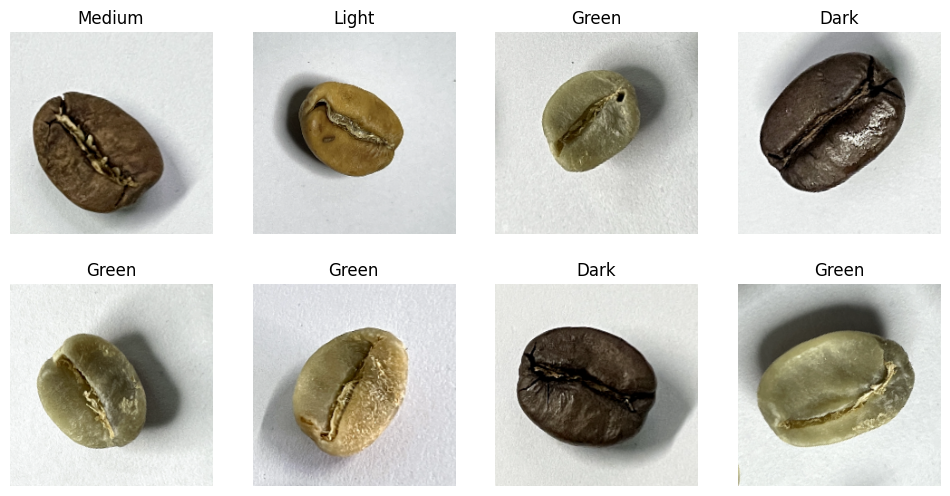

In [5]:
from fastai.vision.all import *

dls = ImageDataLoaders.from_folder(
    train_dir,
    valid_pct=0.2, seed=42,
    item_tfms=Resize(224),
    # Aumento de dados: giros e espelhamentos, SEM alterar brilho/contraste.
    # Motivo: mudar o brilho de um grão claro pode fazê-lo parecer de torra média,
    # e o modelo aprenderia o rótulo errado. Escolha de domínio, não de técnica.
    batch_tfms=aug_transforms(max_lighting=0.0, max_rotate=180.0, do_flip=True, flip_vert=True),
    bs=64,
)
print("Classes:", dls.vocab)
dls.show_batch(max_n=8)

In [8]:
learn = vision_learner(dls, resnet34, metrics=accuracy)
learn.fine_tune(3)   # 3 épocas costuma bastar; leva poucos minutos na GPU

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 140MB/s] 


epoch,train_loss,valid_loss,accuracy,time
0,1.203801,0.286122,0.900000,00:08


epoch,train_loss,valid_loss,accuracy,time
0,0.209507,0.065457,0.975000,00:06
1,0.150207,0.035988,0.991667,00:06
2,0.110083,0.020797,0.995833,00:06


### Onde o modelo erra?
A matriz de confusão mostra quais classes ele confunde. As *top losses* mostram as imagens em que ele errou com mais confiança — muitas vezes revelam erro de rótulo na própria base.

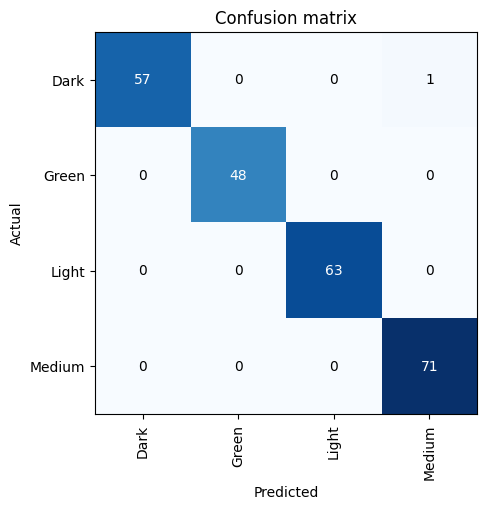

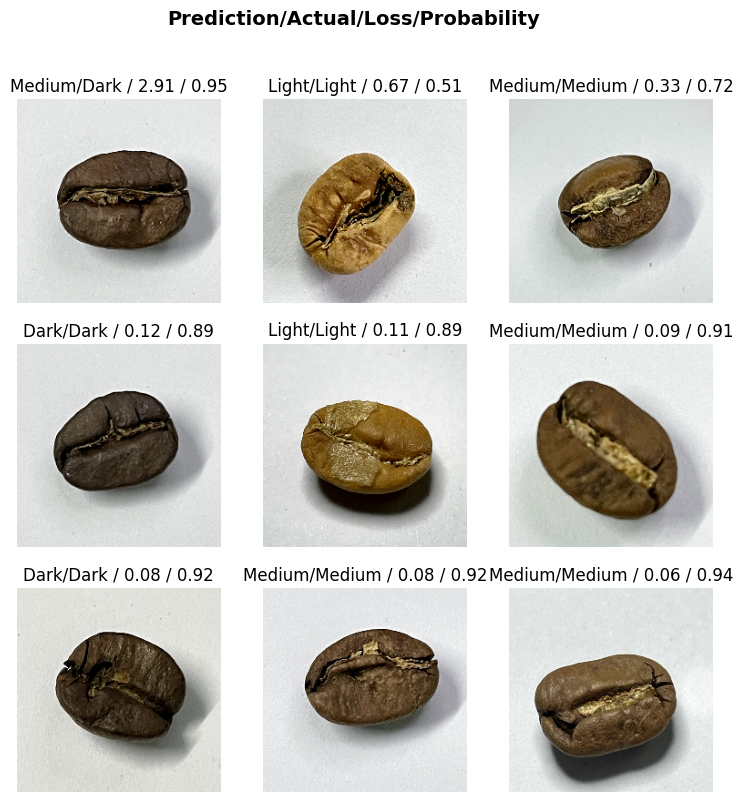

In [9]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix(figsize=(5, 5))
interp.plot_top_losses(9, nrows=3)

## 5. Teste cego (o número que vale)

Acurácia no teste cego: 99.8%  (400 imagens)

              precision    recall  f1-score   support

        Dark       0.99      1.00      1.00       100
       Green       1.00      1.00      1.00       100
       Light       1.00      1.00      1.00       100
      Medium       1.00      0.99      0.99       100

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg       1.00      1.00      1.00       400



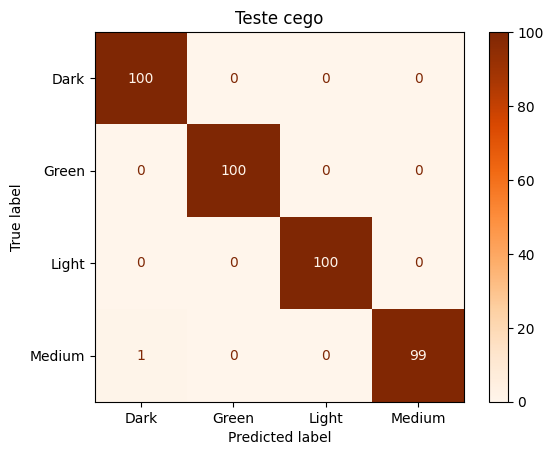

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

test_files = imagens(test_dir)
test_dl = dls.test_dl(test_files, with_labels=True)
preds, targs = learn.get_preds(dl=test_dl)
pred_idx = preds.argmax(1)

acc_teste = (pred_idx == targs).float().mean().item()
print(f"Acurácia no teste cego: {acc_teste:.1%}  ({len(test_files)} imagens)\n")
print(classification_report(targs, pred_idx, target_names=list(dls.vocab)))

ConfusionMatrixDisplay(confusion_matrix(targs, pred_idx), display_labels=list(dls.vocab)).plot(cmap="Oranges")
plt.title("Teste cego"); plt.show()

## 6. Abordagem 3 — Modelo multimodal (Claude), sem treino

Mesmas imagens, nenhuma etapa de treino: só uma instrução em texto. Usamos uma amostra de 40 imagens do teste (10 por classe) para manter o custo baixo — e rodamos o modelo treinado **na mesma amostra**, para a comparação ser justa.

**Configuração:** crie uma chave em [console.anthropic.com](https://console.anthropic.com). Ao rodar a célula, uma caixa vai pedir a chave: cole e tecle Enter. Ela não fica gravada no arquivo, então não vai parar no GitHub. O custo de 40 imagens é de centavos.

In [ ]:
import anthropic, base64, json, time
from getpass import getpass

client = anthropic.Anthropic(api_key=getpass("Cole sua chave da API da Anthropic: "))
MODELO = "claude-sonnet-5-5"
rotulos = list(dls.vocab)

PROMPT = (
    "Esta é uma foto de grãos de café. Classifique o nível de torra como "
    f"um destes: {', '.join(rotulos)}. (Green = grão cru, sem torra.)"
)
# A resposta só pode ser um dos rótulos (structured output): nada de texto livre para interpretar
FORMATO = {"type": "json_schema", "schema": {
    "type": "object",
    "properties": {"torra": {"type": "string", "enum": rotulos}},
    "required": ["torra"], "additionalProperties": False,
}}

def classificar_claude(caminho):
    dados = base64.standard_b64encode(Path(caminho).read_bytes()).decode("utf-8")
    tipo = "image/png" if Path(caminho).suffix.lower() == ".png" else "image/jpeg"
    resp = client.beta.messages.create(
        model=MODELO,
        max_tokens=1024,   # folga para o modelo "pensar" antes de responder
        output_config={"effort": "low", "format": FORMATO},
        betas=["server-side-fallback-2026-07-01"],
        fallbacks="default",   # se o modelo recusar, a API tenta outro modelo automaticamente
        messages=[{"role": "user", "content": [
            {"type": "image", "source": {"type": "base64", "media_type": tipo, "data": dados}},
            {"type": "text", "text": PROMPT},
        ]}],
    )
    if resp.stop_reason != "end_turn":
        return f"? ({resp.stop_reason})"
    # A resposta pode ter blocos de "pensamento" antes do texto: pegamos o bloco de texto
    texto = next(b.text for b in resp.content if b.type == "text")
    return json.loads(texto)["torra"]

random.seed(42)
amostra = []
for c in rotulos:
    amostra += random.sample([f for f in test_files if f.parent.name == c], 10)
print(len(amostra), "imagens na amostra")

In [ ]:
import pandas as pd

linhas = []
for f in amostra:
    t0 = time.time(); claude = classificar_claude(f); t_claude = time.time() - t0
    t0 = time.time(); fastai_pred = learn.predict(f)[0]; t_fastai = time.time() - t0
    linhas.append({"arquivo": f.name, "real": f.parent.name,
                   "fastai": fastai_pred, "claude": claude,
                   "seg_fastai": t_fastai, "seg_claude": t_claude})

res = pd.DataFrame(linhas)
resumo = pd.DataFrame({
    "acurácia": [(res.fastai == res.real).mean(), (res.claude == res.real).mean()],
    "tempo médio por imagem (s)": [res.seg_fastai.mean(), res.seg_claude.mean()],
}, index=["Modelo treinado (fast.ai)", "Claude (sem treino)"])
resumo.style.format({"acurácia": "{:.0%}", "tempo médio por imagem (s)": "{:.2f}"})

In [ ]:
# Onde cada abordagem errou? (compare com a matriz de confusão do modelo treinado)
pd.crosstab(res.real, res.claude, rownames=["Real"], colnames=["Claude disse"])

**Para pensar:** o Claude erra nas mesmas classes que o modelo treinado? Ele nunca viu essa base nem a escala de torra usada pelos autores — então parte do "erro" pode ser diferença de definição (o que é *Light* para quem rotulou × para o modelo), não incapacidade de ver.

## 7. Salvar o modelo (opcional, recomendado)

Como o servidor do Colab é apagado ao fim da sessão, enviamos o modelo para o **Hugging Face Hub**. Na Semana 4, o app no Hugging Face Spaces vai buscá-lo de lá.

1. Crie uma conta gratuita em https://huggingface.co
2. Em *Settings → Access Tokens*, crie um token do tipo **Write**.
3. Rode a célula e cole o token quando pedir.

In [ ]:
!pip install -q huggingface_hub
from huggingface_hub import login, push_to_hub_fastai, whoami
from getpass import getpass

login(token=getpass("Cole seu token do Hugging Face (Write): "))
usuario = whoami()["name"]
push_to_hub_fastai(learner=learn, repo_id=f"{usuario}/classificador-torra-cafe")
print(f"Modelo publicado em https://huggingface.co/{usuario}/classificador-torra-cafe")

## 8. Diário de resultados (preencha)

| Abordagem | Acurácia | Onde mais errou | Tempo/imagem | Observações |
|---|---|---|---|---|
| Teachable Machine | | | | |
| fast.ai — validação | | | | |
| fast.ai — teste cego | | | | |
| Claude (amostra de 40) | | | | |

**Três perguntas para o post:**
1. Qual abordagem você escolheria se fosse um produto, e por quê? (acurácia, custo, tempo, esforço de manutenção)
2. Qual foi o erro mais revelador?
3. O que essa base **não** testa? (Dica: só um tipo de café, só uma origem, condições de foto controladas.)